# Task 6 — Comprehensive Text-to-Image Pipeline (Oxford-102 Flowers)

**Objective:** Combine the work from the previous internship tasks into one coherent text-to-image pipeline.

### Integrated flow
**User text prompt → CLIP tokenization & text embedding → semantic flower-class matching → Attention-CGAN conditioned generation → generated flower image**

The Stable Diffusion + LoRA model from Task 1 is retained as the higher-quality domain-refined diffusion extension of the same project.

This notebook uses the same five representative Oxford-102 flower classes used in Tasks 2, 5 and 1: **daffodil, sunflower, rose, lotus and hibiscus**.


## 1. Install required libraries
Run this notebook in **Google Colab with GPU enabled**.


In [1]:
!pip -q install transformers safetensors


## 2. Imports and reproducibility


In [2]:
import os
import math
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers import CLIPTokenizer, CLIPTextModel

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)


Device: cuda


## 3. Project configuration
The five classes are kept identical to the earlier CGAN, Attention-CGAN and LoRA experiments.


In [3]:
SELECTED_CLASSES = ["daffodil", "sunflower", "rose", "lotus", "hibiscus"]
NUM_CLASSES = len(SELECTED_CLASSES)
LATENT_DIM = 100
IMAGE_SIZE = 64

class_to_idx = {name: i for i, name in enumerate(SELECTED_CLASSES)}
idx_to_class = {i: name for name, i in class_to_idx.items()}

print("Classes:", SELECTED_CLASSES)
print("Number of classes:", NUM_CLASSES)


Classes: ['daffodil', 'sunflower', 'rose', 'lotus', 'hibiscus']
Number of classes: 5


## 4. Load CLIP text processor
This reuses the text-processing idea from **Task 3**. CLIP converts natural-language prompts into numerical embeddings.


In [4]:
CLIP_MODEL = "openai/clip-vit-base-patch32"

tokenizer = CLIPTokenizer.from_pretrained(CLIP_MODEL)
text_encoder = CLIPTextModel.from_pretrained(CLIP_MODEL).to(DEVICE)
text_encoder.eval()

print("CLIP tokenizer and text encoder loaded.")


tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

[transformers] CLIPTextModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                                            | Status     |  | 
---------------------------------------------------------------+------------+--+-
vision_model.encoder.layers.{0...11}.self_attn.q_proj.bias     | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.mlp.fc1.weight            | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.self_attn.k_proj.weight   | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.mlp.fc2.bias              | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.self_attn.out_proj.weight | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.self_attn.v_proj.weight   | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.self_attn.v_proj.bias     | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.layer_norm2.bias          | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.layer_norm1.weight        | UNEXPECTED |  | 
vision_model.encoder.l

CLIP tokenizer and text encoder loaded.


## 5. Text preprocessing and embedding function


In [5]:
@torch.no_grad()
def encode_text(texts):
    if isinstance(texts, str):
        texts = [texts]

    tokens = tokenizer(
        texts,
        padding=True,
        truncation=True,
        max_length=32,
        return_tensors="pt"
    ).to(DEVICE)

    outputs = text_encoder(**tokens)
    embeddings = outputs.pooler_output
    embeddings = F.normalize(embeddings, dim=-1)
    return embeddings

example = "a bright yellow sunflower in bloom"
example_embedding = encode_text(example)
print("Prompt:", example)
print("Embedding shape:", tuple(example_embedding.shape))


Prompt: a bright yellow sunflower in bloom
Embedding shape: (1, 512)


## 6. Create semantic embeddings for the supported flower classes
Each supported class is represented using a natural-language prototype prompt. The user's prompt will be compared with these embeddings using cosine similarity.


In [6]:
CLASS_PROMPTS = [f"a detailed photo of a {name} flower" for name in SELECTED_CLASSES]
class_embeddings = encode_text(CLASS_PROMPTS)

for name, prompt in zip(SELECTED_CLASSES, CLASS_PROMPTS):
    print(f"{name:10s} -> {prompt}")


daffodil   -> a detailed photo of a daffodil flower
sunflower  -> a detailed photo of a sunflower flower
rose       -> a detailed photo of a rose flower
lotus      -> a detailed photo of a lotus flower
hibiscus   -> a detailed photo of a hibiscus flower


## 7. Match free text to a flower condition
This bridges **Task 3 (text embeddings)** and **Task 5 (conditional image generation)**.


In [7]:
@torch.no_grad()
def match_flower_class(prompt, show_scores=True):
    prompt_embedding = encode_text(prompt)
    similarities = (prompt_embedding @ class_embeddings.T).squeeze(0)
    best_idx = int(torch.argmax(similarities).item())
    best_class = idx_to_class[best_idx]

    if show_scores:
        print("Input prompt:", prompt)
        print("\nCLIP similarity scores:")
        for name, score in zip(SELECTED_CLASSES, similarities.detach().cpu().tolist()):
            print(f"  {name:10s}: {score:.4f}")
        print("\nSelected condition:", best_class)

    return best_idx, best_class, similarities.detach().cpu()

_ = match_flower_class("a large red hibiscus with open petals")


Input prompt: a large red hibiscus with open petals

CLIP similarity scores:
  daffodil  : 0.4384
  sunflower : 0.4545
  rose      : 0.4964
  lotus     : 0.3721
  hibiscus  : 0.7648

Selected condition: hibiscus


## 8. Attention-CGAN architecture
This is the image-generation component from **Task 5**. Self-attention helps the generator and discriminator model relationships between distant image regions.


In [8]:
class SelfAttention(nn.Module):
    def __init__(self, channels):
        super().__init__()
        reduced = max(1, channels // 8)
        self.query = nn.Conv2d(channels, reduced, 1)
        self.key = nn.Conv2d(channels, reduced, 1)
        self.value = nn.Conv2d(channels, channels, 1)
        self.gamma = nn.Parameter(torch.zeros(1))

    def forward(self, x):
        b, c, h, w = x.shape
        q = self.query(x).view(b, -1, h*w).permute(0, 2, 1)
        k = self.key(x).view(b, -1, h*w)
        attention = torch.softmax(torch.bmm(q, k), dim=-1)
        v = self.value(x).view(b, c, h*w)
        out = torch.bmm(v, attention.permute(0, 2, 1)).view(b, c, h, w)
        return self.gamma * out + x


class AttentionGenerator(nn.Module):
    def __init__(self, latent_dim=100, num_classes=5, embed_dim=50):
        super().__init__()
        self.label_embedding = nn.Embedding(num_classes, embed_dim)
        in_dim = latent_dim + embed_dim

        self.fc = nn.Sequential(
            nn.Linear(in_dim, 512 * 4 * 4),
            nn.BatchNorm1d(512 * 4 * 4),
            nn.ReLU(True)
        )
        self.net = nn.Sequential(
            nn.ConvTranspose2d(512, 256, 4, 2, 1, bias=False),
            nn.BatchNorm2d(256), nn.ReLU(True),
            nn.ConvTranspose2d(256, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128), nn.ReLU(True),
            SelfAttention(128),
            nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False),
            nn.BatchNorm2d(64), nn.ReLU(True),
            nn.ConvTranspose2d(64, 3, 4, 2, 1, bias=False),
            nn.Tanh()
        )

    def forward(self, noise, labels):
        label_vec = self.label_embedding(labels)
        x = torch.cat([noise, label_vec], dim=1)
        x = self.fc(x).view(-1, 512, 4, 4)
        return self.net(x)


class AttentionDiscriminator(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()
        self.label_embedding = nn.Embedding(num_classes, 64 * 64)
        self.net = nn.Sequential(
            nn.Conv2d(4, 64, 4, 2, 1), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(64, 128, 4, 2, 1), nn.BatchNorm2d(128), nn.LeakyReLU(0.2, inplace=True),
            SelfAttention(128),
            nn.Conv2d(128, 256, 4, 2, 1), nn.BatchNorm2d(256), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(256, 512, 4, 2, 1), nn.BatchNorm2d(512), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(512, 1, 4, 1, 0)
        )

    def forward(self, images, labels):
        label_map = self.label_embedding(labels).view(-1, 1, 64, 64)
        x = torch.cat([images, label_map], dim=1)
        return self.net(x).view(-1)

G = AttentionGenerator(LATENT_DIM, NUM_CLASSES).to(DEVICE)
print("Attention-CGAN generator created.")


Attention-CGAN generator created.


## 9. Load the trained Task 5 generator
Upload/copy the **trained Attention-CGAN generator weight file from Task 5** into Colab and set its path below.

If Task 5 saved the generator under a slightly different filename, change only `GENERATOR_WEIGHTS`.


In [9]:
GENERATOR_WEIGHTS = Path("/content/attention_generator.pth")

if GENERATOR_WEIGHTS.exists():
    state = torch.load(GENERATOR_WEIGHTS, map_location=DEVICE)
    G.load_state_dict(state)
    G.eval()
    GENERATOR_READY = True
    print("✅ Task 5 Attention-CGAN weights loaded:", GENERATOR_WEIGHTS)
else:
    GENERATOR_READY = False
    print("⚠️ Generator weights not found at:", GENERATOR_WEIGHTS)
    print("Upload the trained Task 5 generator .pth file and update GENERATOR_WEIGHTS.")


⚠️ Generator weights not found at: /content/attention_generator.pth
Upload the trained Task 5 generator .pth file and update GENERATOR_WEIGHTS.


## 10. Final integrated text-to-image function
The user can now enter natural language. CLIP interprets the text, selects the closest supported flower condition, and the trained Attention-CGAN generates the image.


In [10]:
@torch.no_grad()
def text_to_flower(prompt, seed=42):
    if not GENERATOR_READY:
        raise FileNotFoundError(
            "Task 5 generator weights are not loaded. Upload the trained generator and rerun Section 9."
        )

    class_idx, class_name, scores = match_flower_class(prompt, show_scores=False)

    generator = torch.Generator(device=DEVICE).manual_seed(seed)
    noise = torch.randn(1, LATENT_DIM, generator=generator, device=DEVICE)
    label = torch.tensor([class_idx], dtype=torch.long, device=DEVICE)

    G.eval()
    generated = G(noise, label)[0].detach().cpu()
    generated = (generated + 1) / 2
    generated = generated.clamp(0, 1)

    print("User prompt:", prompt)
    print("Matched flower class:", class_name)
    print("Generator: Attention-CGAN")

    image_np = generated.permute(1, 2, 0).numpy()
    plt.figure(figsize=(5, 5))
    plt.imshow(image_np)
    plt.title(f"Prompt → {class_name}")
    plt.axis("off")
    plt.show()

    return image_np, class_name, scores


## 11. Demo prompts
Run this after loading the trained Task 5 generator.


In [11]:
TEST_PROMPTS = [
    "a beautiful yellow flower with a dark center like the sun",
    "a soft pink lotus blooming on water",
    "a vivid red hibiscus with large petals",
]

if GENERATOR_READY:
    demo_results = []
    for i, prompt in enumerate(TEST_PROMPTS):
        image, matched_class, scores = text_to_flower(prompt, seed=SEED + i)
        demo_results.append((prompt, matched_class, image))
else:
    print("Upload the Task 5 generator weights first, then rerun this cell.")


Upload the Task 5 generator weights first, then rerun this cell.


## 12. Visualize the semantic matching stage
This provides evidence that the natural-language prompt is being converted into a class condition rather than manually choosing the label.


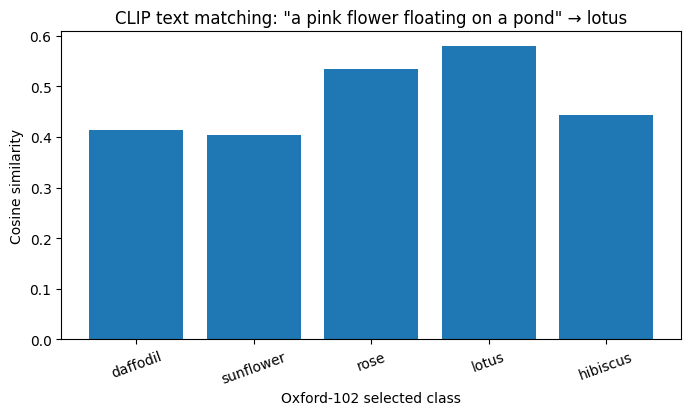

Predicted condition: lotus


In [12]:
prompt = "a pink flower floating on a pond"
_, predicted_class, scores = match_flower_class(prompt, show_scores=False)

plt.figure(figsize=(8, 4))
plt.bar(SELECTED_CLASSES, scores.numpy())
plt.ylabel("Cosine similarity")
plt.xlabel("Oxford-102 selected class")
plt.title(f'CLIP text matching: "{prompt}" → {predicted_class}')
plt.xticks(rotation=20)
plt.show()

print("Predicted condition:", predicted_class)


## 13. Stable Diffusion LoRA extension from Task 1
The Attention-CGAN above demonstrates the required GAN-based end-to-end pipeline. **Task 1** adds a second, higher-resolution branch: Stable Diffusion v1.5 refined with LoRA on the same Oxford-102 flower domain.

Conceptually:

**Prompt → CLIP/Text Encoder → Attention-CGAN (64×64 GAN output)**

and the domain-refined extension:

**Prompt → Stable Diffusion v1.5 + Oxford-102 LoRA → higher-resolution flower output**

Keeping the LoRA experiment as a separate trained model avoids retraining it inside this final integration notebook.


## 14. Complete project mapping

| Internship Task | Component in the unified Oxford-102 project |
|---|---|
| Task 4 | Oxford-102 dataset loading, statistics and visualization |
| Task 3 | CLIP tokenization, preprocessing and text embeddings |
| Task 2 | Conditional GAN conditioned on flower categories |
| Task 5 | Self-attention enhanced Conditional GAN |
| Task 1 | Stable Diffusion v1.5 LoRA domain refinement |
| **Task 6** | **Integrated prompt → embedding → semantic condition → GAN image pipeline** |

This demonstrates that the internship tasks are progressive experiments and extensions of one text-to-image project rather than unrelated standalone projects.


## 15. Conclusion

A comprehensive text-to-image pipeline was created for the Oxford-102 flower domain. Natural-language prompts are tokenized and encoded with CLIP, compared semantically with the supported flower categories, and converted into conditioning labels for the Attention-CGAN. The GAN then generates the corresponding flower visual. The same project also includes a LoRA-refined Stable Diffusion model for higher-quality domain-specific generation.

### Final pipeline
**Text prompt → tokenization → CLIP embedding → cosine-similarity class matching → Attention-CGAN conditioning → generated image**

This final task integrates the text-processing, GAN, attention and diffusion experiments developed across the internship.
